# Fixed detector priors (step2)
The SnowStorm detector priors were not applied in the earlier fits: NNMFit only reads the key `prior`, the config used `priors`.
The fits were re-run with the fixed key (`..._fixedprior`). Here: the previous HESE results, the fit without detector priors and the
fit with fixed priors, all SAY; the new SAY vs Poisson fit; and the data flavor triangle without and with detector priors.


In [2]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import NNMFit

sys.path.insert(0, "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind")
from analysis_utils import (scan_errors, CombinedScan, combine_2d_scans, load_hese75_2d, PREVIOUS_RESULTS,
                            load_triangle_scan, combine_scans, flavor_fractions, latex_comparison_table, PARAMETERS)

plotting_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind/studies/plots_compare_fixedprior"
os.makedirs(plotting_path, exist_ok=True)

In [3]:
import matplotlib.font_manager as font_manager
font_axis_label = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 22,
        }
font_title = {'family': 'serif',
        'color':  'black',
        'weight': 'bold',
        'size': 20,
        }
font_legend = font_manager.FontProperties(family='serif',
                                   weight='normal',
                                   style='normal', size=13)

plt.rcParams["figure.figsize"] = (6,6)
plt.rcParams.update({'font.family':'serif'})

## 1D scans

In [4]:
data_fits = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step2_hese_flavor_reunblind/data_fits"
scan = "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE"
drop_unsuccessful = True  # as in fit_result.ipynb
scan_dirs = {
    "wrong":   f"{data_fits}/{scan}",
    "SAY":     f"{data_fits}/{scan}_fixedprior",
    "Poisson": f"{data_fits}/{scan}_Poisson_fixedprior",
}
scan_dict = {name: NNMFit.utilities.ScanHandler(d, dump=False, drop_unsuccessful=drop_unsuccessful) for name, d in scan_dirs.items()}
bestfits = {name: s.get_freefit(drop_unsuccessful="True") for name, s in scan_dict.items()}
errors = {name: scan_errors(scan_dict[name], bestfits[name], PARAMETERS, drop_unsuccessful) for name in scan_dict}
for name, bf in bestfits.items():
    print(f"{name}: freefit llh = {bf['llh']:.4f}")

wrong: freefit llh = 179.3310
SAY: freefit llh = 180.9516
Poisson: freefit llh = 94.0038


In [5]:
def show(columns, parameters):
    df = pd.DataFrame({(name, col): {p: (v[i] if v is not None and v[i] is not None else np.nan) for p, v in res.items()}
                       for name, res in columns.items() for i, col in enumerate(["bestfit", "-1sig", "+1sig"])})
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 250, "display.max_columns", 30):
        display(df.reindex(parameters))

## SAY: previous HESE results, without detector priors, with fixed priors

In [6]:
say_columns = {
    "HESE-7.5":           PREVIOUS_RESULTS["HESE-7.5"],
    "HESE-7.5 flavor":    PREVIOUS_RESULTS["HESE-7.5 flavor"],
    "HESE-12 flavor":     PREVIOUS_RESULTS["HESE-12 flavor"],
    "no detector priors": errors["wrong"],
    "fixed priors":       errors["SAY"],
}
show(say_columns, PARAMETERS)
print(latex_comparison_table(say_columns,
                             caption=r"Step2 best fit values with $1\sigma$ asymmetric uncertainties (SAY): previous HESE results, "
                                     r"this analysis without the detector priors, and with the detector priors applied.",
                             label="tab:step2_fixedprior"))

HESE-7.5             HESE-7.5 flavor             HESE-12 flavor             no detector priors             fixed priors            
                       bestfit -1sig +1sig         bestfit -1sig +1sig        bestfit -1sig +1sig            bestfit -1sig +1sig      bestfit -1sig +1sig
astro_norm               2.123 0.540 0.487           3.001   NaN   NaN          2.530 1.490 1.780              3.615 1.215 1.617        3.221 1.107 1.515
gamma_astro              2.870 0.190 0.210           2.890 0.200 0.210          2.840 0.180 0.190              2.932 0.160 0.136        2.860 0.151 0.164
astro_nue_ratio            NaN   NaN   NaN           0.674   NaN   NaN          0.450 0.400 0.680              0.897 0.277 0.398        0.745 0.182 0.351
astro_nutau_ratio          NaN   NaN   NaN           0.651   NaN   NaN          0.896 0.890 1.340              0.001   NaN 0.189        0.037   NaN 0.285
conv_norm                1.010 0.340 0.340           0.970 0.360 0.360          0.990 0.200 0.190              1.024 0.186 0.183        1.006 0.183 0.190
prompt_norm              0.000 0.000 5.340           0.000 0.000 6.100          0.000 0.000 2.250              0.155   NaN 2.548        1.390   NaN 2.614
combined_muongun_norm    1.190 0.440 0.450           1.160 0.450 0.460          1.160 0.430 0.420              0.510 0.191 0.236        0.487 0.086 0.226
muongun_asymmetry          NaN   NaN   NaN             NaN   NaN   NaN            NaN   NaN   NaN              0.165 0.796   NaN        0.242 0.852   NaN
delta_gamma             -0.053 0.131 0.048             NaN   NaN   NaN         -0.000 1.000 1.000             -0.003 0.049 0.047       -0.002 0.049 0.049
CR_grad                    NaN   NaN   NaN             NaN   NaN   NaN          0.042 1.000 2.000             -0.076 0.915 0.906       -0.010 0.952 0.895
barr_h                     NaN   NaN   NaN             NaN   NaN   NaN          0.000 0.500 0.500              0.003 0.148 0.139        0.001 0.147 0.147
barr_w                     NaN   NaN   NaN             NaN   NaN   NaN          0.000 0.500 0.500             -0.003 0.378 0.401       -0.000 0.398 0.397
barr_y                     NaN   NaN   NaN             NaN   NaN   NaN          0.000 0.500 0.500              0.048 0.271 0.273        0.015 0.282 0.285
barr_z                     NaN   NaN   NaN             NaN   NaN   NaN          0.000 0.500 0.500              0.027 0.108 0.106        0.011 0.107 0.110
dom_eff                  0.952 0.066 0.093             NaN   NaN   NaN          1.040 0.040 0.060              0.923   NaN 0.095        0.984   NaN 0.046
ice_scat                   NaN   NaN   NaN             NaN   NaN   NaN          0.980 0.040 0.040              0.927   NaN 0.089        0.992 0.038 0.036
ice_abs                    NaN   NaN   NaN             NaN   NaN   NaN          0.990 0.040 0.040              1.088 0.072   NaN        1.026 0.038 0.036
ice_crystal                NaN   NaN   NaN             NaN   NaN   NaN            NaN   NaN   NaN              0.800   NaN 0.079        0.924 0.071 0.074
ice_holep0                 NaN   NaN   NaN             NaN   NaN   NaN         -0.270 0.380 0.280             -0.024   NaN 0.210        0.066   NaN 0.185
ice_holep1                 NaN   NaN   NaN             NaN   NaN   NaN         -0.080 0.050 0.040             -0.100   NaN 0.065       -0.063 0.029 0.028

\begin{table}[h]
  \centering
  \caption{Step2 best fit values with $1\sigma$ asymmetric uncertainties (SAY): previous HESE results, this analysis without the detector priors, and with the detector priors applied.}
  \label{tab:step2_fixedprior}
  \begin{tabular}{l r r r r r}
    \hline\hline
    Parameter & HESE-7.5 & HESE-7.5 flavor & HESE-12 flavor & no detector priors & fixed priors \\
    \hline
    \hline
    \multicolumn{6}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $2.123^{+0.487}_{-0.540}$ & $3.001$ & $2.530^{+1.780}_{-1.490}$ & $3.615^{+1.617}_{-1.215}$ & $3.221^{+1.515}_{-1.107}$ \\
    $\gamma_\mathrm{astro}$ & $2.870^{+0.210}_{-0.190}$ & $2.890^{+0.210}_{-0.200}$ & $2.840^{+0.190}_{-0.180}$ & $2.932^{+0.136}_{-0.160}$ & $2.860^{+0.164}_{-0.151}$ \\
    $\Phi_{\nu_e}/\Phi_{\nu_\mu}$ & --- & $0.674$ & $0.450^{+0.680}_{-0.400}$ & $0.897^{+0.398}_{-0.277}$ & $0.745^{+0.351}_{-0.182}$ \\
    $\Phi_{\nu_\tau}/\Phi_{\nu_\mu}$ & --- & $0.651$ & $0.896^{+1.340}_{-0.

## Fixed priors: SAY vs Poisson

In [7]:
likelihood_columns = {"SAY": errors["SAY"], "Poisson": errors["Poisson"]}
show(likelihood_columns, PARAMETERS)
print(latex_comparison_table(likelihood_columns,
                             caption=r"Step2 best fit values with $1\sigma$ asymmetric uncertainties with the detector priors applied, "
                                     r"for the SAY and the Poisson likelihood.",
                             label="tab:step2_fixedprior_SAY_Poisson"))

SAY             Poisson            
                      bestfit -1sig +1sig bestfit -1sig +1sig
astro_norm              3.221 1.107 1.515   3.185 1.065 1.428
gamma_astro             2.860 0.151 0.164   2.853 0.152 0.155
astro_nue_ratio         0.745 0.182 0.351   0.740 0.175 0.393
astro_nutau_ratio       0.037   NaN 0.285   0.065   NaN 0.270
conv_norm               1.006 0.183 0.190   1.005 0.187 0.190
prompt_norm             1.390   NaN 2.614   1.674   NaN 2.626
combined_muongun_norm   0.487 0.086 0.226   0.726 0.231 0.262
muongun_asymmetry       0.242 0.852   NaN   1.000 1.042   NaN
delta_gamma            -0.002 0.049 0.049  -0.002 0.049 0.049
CR_grad                -0.010 0.952 0.895  -0.001 0.953 0.934
barr_h                  0.001 0.147 0.147   0.000 0.147 0.147
barr_w                 -0.000 0.398 0.397  -0.002 0.397 0.398
barr_y                  0.015 0.282 0.285   0.014 0.282 0.285
barr_z                  0.011 0.107 0.110   0.011 0.107 0.110
dom_eff                 0.984   NaN 0.046   0.981 0.056 0.053
ice_scat                0.992 0.038 0.036   0.990 0.039 0.039
ice_abs                 1.026 0.038 0.036   1.031 0.038 0.036
ice_crystal             0.924 0.071 0.074   0.913 0.080 0.079
ice_holep0              0.066   NaN 0.185   0.033   NaN 0.211
ice_holep1             -0.063 0.029 0.028  -0.064 0.031 0.031

\begin{table}[h]
  \centering
  \caption{Step2 best fit values with $1\sigma$ asymmetric uncertainties with the detector priors applied, for the SAY and the Poisson likelihood.}
  \label{tab:step2_fixedprior_SAY_Poisson}
  \begin{tabular}{l r r}
    \hline\hline
    Parameter & SAY & Poisson \\
    \hline
    \hline
    \multicolumn{3}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $3.221^{+1.515}_{-1.107}$ & $3.185^{+1.428}_{-1.065}$ \\
    $\gamma_\mathrm{astro}$ & $2.860^{+0.164}_{-0.151}$ & $2.853^{+0.155}_{-0.152}$ \\
    $\Phi_{\nu_e}/\Phi_{\nu_\mu}$ & $0.745^{+0.351}_{-0.182}$ & $0.740^{+0.393}_{-0.175}$ \\
    $\Phi_{\nu_\tau}/\Phi_{\nu_\mu}$ & $0.037^{+0.285}_{---}$ & $0.065^{+0.270}_{---}$ \\
    \hline
    \multicolumn{3}{l}{\textbf{Flux nuisance}} \\
    \hline
    $\Phi_\mathrm{conv}$ & $1.006^{+0.190}_{-0.183}$ & $1.005^{+0.190}_{-0.187}$ \\
    $\Phi_\mathrm{prompt}$ & $1.390^{+2.614}_{---}$ & $1.674^{+2.626}_{---}$ \\
    $\Phi_\mathrm{muon}$ & $0.487^{+0.22

## Flavor triangle
Without detector priors: the three scans `nbestfit50_fine_{0,1,2}` combined (as in `flavor_triangle.ipynb`); with fixed priors:
`nbestfit50_fixedprior_0`; Poisson with fixed priors: `nbestfit50_Poisson_fixedprior_0`. All scan points are used (`drop_unsuccessful_points=False`, see `asimov_closure.ipynb`).

In [8]:
sys.path.append("/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks")
from plot_utils_triangle import *

triangle_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step2_hese_flavor_reunblind/data_fits_flavor_triangle"
tri_scan_dirs = {
    "nbestfit50_fine_0":       f"{triangle_path}/nbestfit50_fine_0",
    "nbestfit50_fine_1":       f"{triangle_path}/nbestfit50_fine_1",
    "nbestfit50_fine_2":       f"{triangle_path}/nbestfit50_fine_2",
    "nbestfit50_fixedprior_0": f"{triangle_path}/nbestfit50_fixedprior_0",
    "nbestfit50_Poisson_fixedprior_0": f"{triangle_path}/nbestfit50_Poisson_fixedprior_0",
}
N_grid = 40
tri_scans, tri_data, tri_bestfits = {}, {}, {}
for name, scan_dir in tri_scan_dirs.items():
    tri_scans[name], tri_data[name], tri_bestfits[name] = load_triangle_scan(scan_dir, N_grid=N_grid, drop_unsuccessful_points=False)
    print(f"{name}: {tri_data[name]['n_converged']} converged, {len(tri_data[name]['ts'])} used scan points, "
          f"freefit llh = {tri_bestfits[name]['llh']:.4f}")

tri_data["no detector priors"], tri_bestfits["no detector priors"] = combine_scans(
    ["nbestfit50_fine_0", "nbestfit50_fine_1", "nbestfit50_fine_2"], tri_data, tri_bestfits, N_grid)
tri_data["fixed priors"], tri_bestfits["fixed priors"] = tri_data["nbestfit50_fixedprior_0"], tri_bestfits["nbestfit50_fixedprior_0"]
tri_data["Poisson, fixed priors"] = tri_data["nbestfit50_Poisson_fixedprior_0"]
tri_bestfits["Poisson, fixed priors"] = tri_bestfits["nbestfit50_Poisson_fixedprior_0"]
tri_names = ["no detector priors", "fixed priors", "Poisson, fixed priors"]

tri_parameters = ["astro_norm", "gamma_astro", "astro_nue_ratio", "astro_nutau_ratio", "f_e", "f_mu", "f_tau"]
tri_results = {name: {**{p: tri_bestfits[name][p] for p in tri_parameters[:4]}, **flavor_fractions(tri_bestfits[name])}
               for name in tri_names}
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pd.DataFrame(tri_results).loc[tri_parameters])

removed stuff
nbestfit50_fine_0: 238 converged, 270 used scan points, freefit llh = 179.3335
removed stuff
nbestfit50_fine_1: 240 converged, 270 used scan points, freefit llh = 179.3313
removed stuff
nbestfit50_fine_2: 247 converged, 270 used scan points, freefit llh = 179.3309
removed stuff
nbestfit50_fixedprior_0: 203 converged, 269 used scan points, freefit llh = 180.9516
removed stuff
Global best fit from: nbestfit50_fine_2 (llh=179.3309)
Combined scan points: 270


,no detector priors,fixed priors
astro_norm,3.640,3.222
gamma_astro,2.934,2.860
astro_nue_ratio,0.895,0.745
astro_nutau_ratio,0.002,0.037
f_e,0.472,0.418
f_mu,0.527,0.561
f_tau,0.001,0.020


/data/user/tvaneede/utils/Ternary.py:74: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.xaxis.grid(*args, **kwargs)


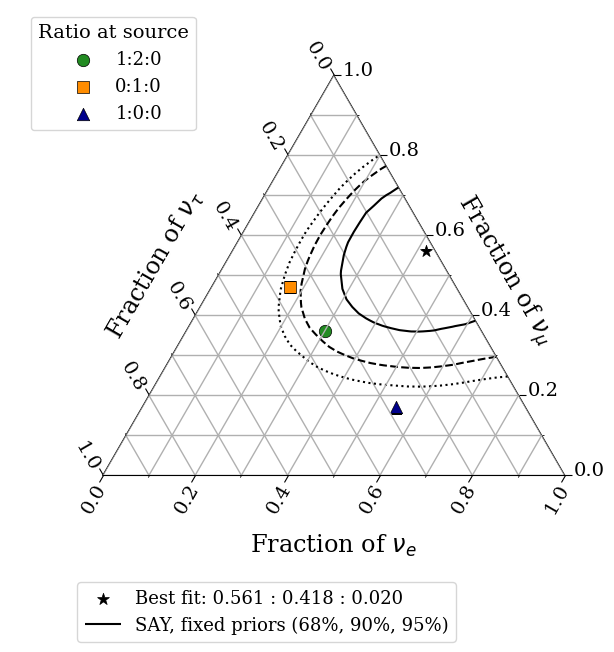

In [9]:
fr = flavor_fractions(tri_bestfits["fixed priors"])
C = plot_contour(data=tri_data, name="fixed priors", label="SAY, fixed priors", levels=["68%", "90%", "95%"], title="",
                 scenarios=True, show_ts_labels=False, bestfit=[fr["f_tau"], fr["f_e"]],
                 savepath=f"{plotting_path}/flavor_triangle_fixedprior.png")
plt.show()

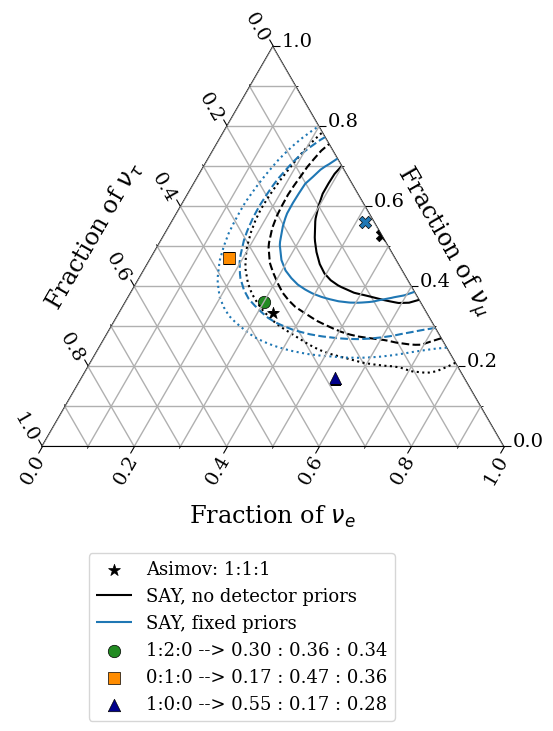

In [10]:
tri_labels = {"no detector priors": "SAY, no detector priors", "fixed priors": "SAY, fixed priors",
              "Poisson, fixed priors": "Poisson, fixed priors"}

def plot_triangles(names, savepath):
    C = compare_contours(tri_data, names=names, labels=[tri_labels[n] for n in names],
                         levels=["68%", "90%", "95%"], title="", scenarios=True)
    ax = plt.gca()
    for i, name in enumerate(names):
        fr = flavor_fractions(tri_bestfits[name])
        ax.scatter([fr["f_tau"]], [fr["f_e"]], marker="X", facecolor=colours[i], edgecolor="k", lw=0.5, s=80, zorder=10)
    plt.savefig(savepath, bbox_inches="tight")
    plt.show()

plot_triangles(["no detector priors", "fixed priors"], f"{plotting_path}/flavor_triangle_wrong_vs_fixedprior.png")
plot_triangles(["fixed priors", "Poisson, fixed priors"], f"{plotting_path}/flavor_triangle_fixedprior_SAY_vs_Poisson.png")
plot_triangles(tri_names, f"{plotting_path}/flavor_triangle_wrong_fixedprior_Poisson.png")